In [55]:
# add libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import warnings

In [56]:
# filter warnings
warnings.filterwarnings("ignore")

In [57]:
# read dataset
matad = pd.read_csv('clean_MATA-D_v9.csv')

# Introduction
Human factors is the interdisciplinary study of aligning designs with human capabilities and limitations to learn how people interact with systems, environments, and technology to optimize safety, efficiency, and usability. Human factors research has been a crucial part of reducing accidents in high pressure and high stakes environments. From aviation to nuclear plants, understanding when things go wrong and why informs researchers on how to find preventative measures. In class, one of our discussions argued that technology and data are not neutral and are filled with biases of the people collecting, analyzing, and interpreting data. In a field that relies heavily on objectivity for human factors analysis, the inability to have neutral data can influence how human factors researchers interpret previous accidents and implement solutions.

One Human Reliability Analysis (HRA) method is a second generation method developed by Erik Hollnagel called the Contextual Control Model (COCOM) of Cognitive Reliability and Error Analysis Method (CREAM). CREAM’s goal is to establish “links between the operator’s cognitive grade and human error probability,” otherwise known as HEPs, and give “the probability of occurrence of the operator’s behavior under different control modes” (Pan et al., 2017). COCOM was theorized and built off of CREAM because “human performance was discovered to not be an isolated random action but to be dependent on and controlled by the environment in which the task was completed” (Pan et al., 2017). These HRA methods attempt to better integrate the influences of the environment into human behavior. In work settings, the way in which the tools and signals required for the job are set up directly impacts how humans do their job, how they catch, and how they fix mistakes (Edholm, 1967). While first generation methods addressed behavior rules and physical factors, second generation methods like COCOM attempt to integrate cognitive models as well (Pan et al., 2017).

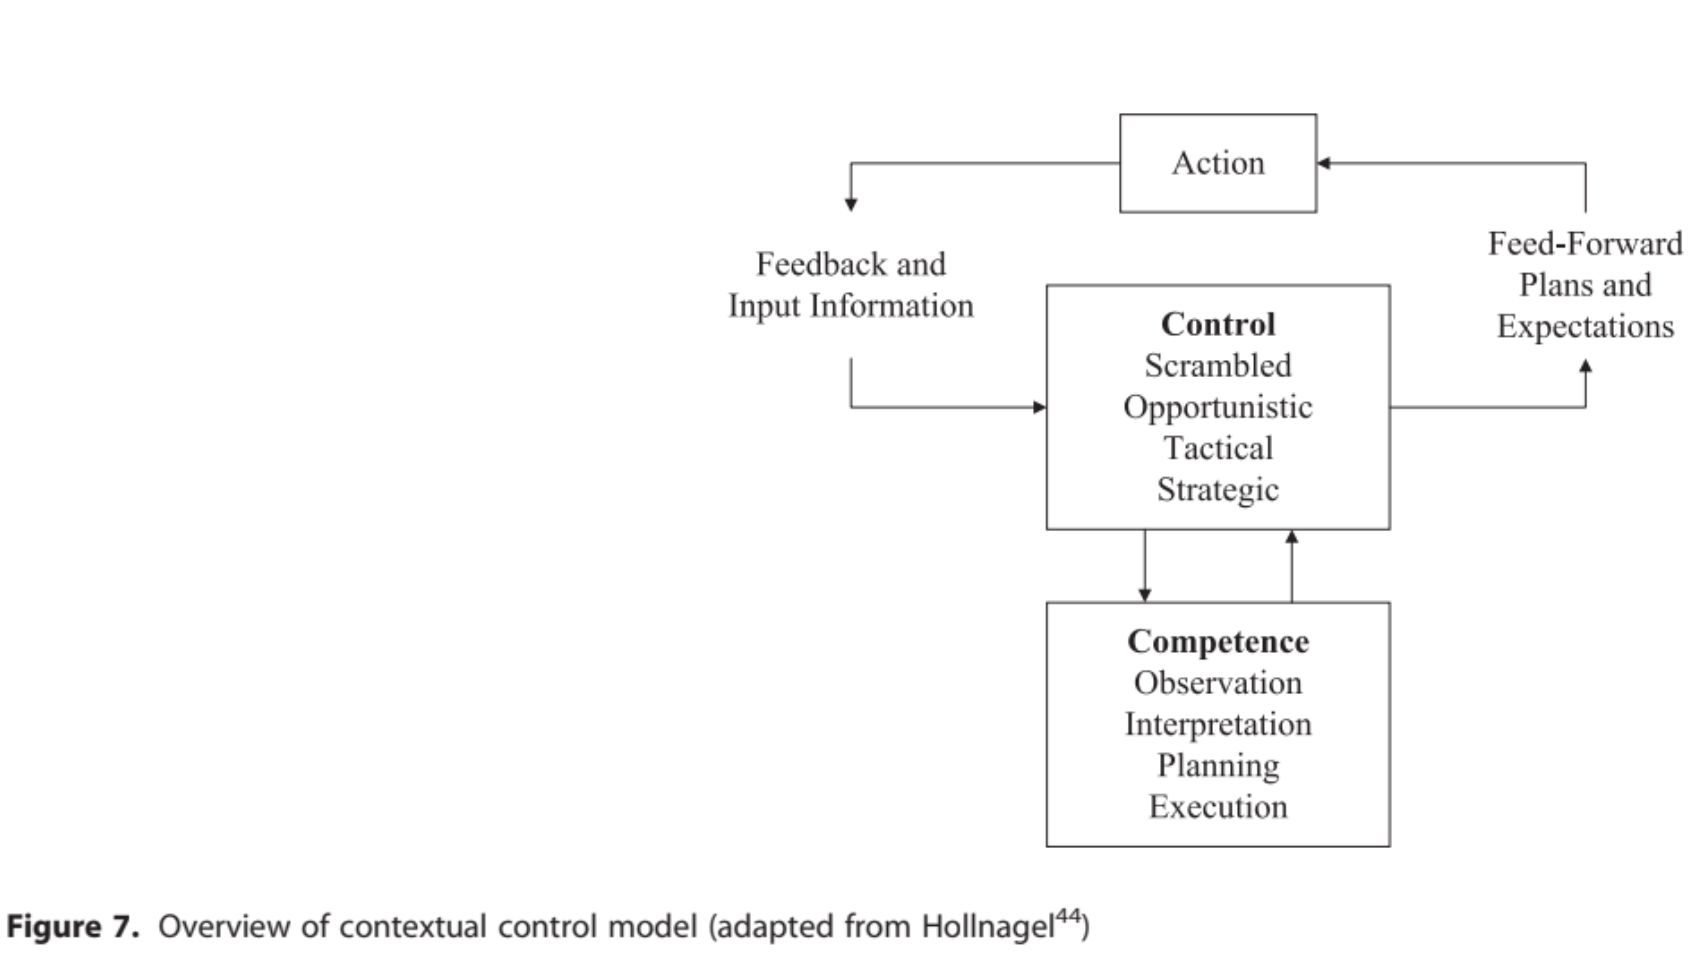

*Figure 1. Screenshot of COCOM model (Pan et al., 2017).*

The Multi-attribute Technological Accidents Dataset (MATA-D) utilizes COCOM to analyze the interactions between human, technology, and organizational factors and classify the types of error observed in “238 major accidents from different industrial backgrounds” from the early 1950s to today (Moura et al., 2016). MATA-D is a widely known and used dataset in human factors research for Human Reliability Analysis (HRA), studying accident prevention, and for risk modeling. Studying MATA-D on the ways it may be biased can help us understand how researchers utilize and interpret its data. The main categorizations we look at are error categorizations on man, technology, and organization. Our goal for this project is to understand if MATA-D is biased towards or away from any of these three categories and in what ways and what information it may lack or have that influences how it is viewed and interpreted. Our research questions to investigate this are (a) Does this dataset put blame on the people instead of the system more than it should, (b) how has the assigned categorization of errors changed over time, and (c) how does the industry affect how errors are made and categorized.

In MATA-D, each incident has the mistakes (marked by a 1) categorized under different classifications of error. The classifications of error are under four broad categories: human, man, technology, and organization. In our analysis, human and man categories were combined to be one human error category. Each tally has a comment with an explanation of the mistake and why it was categorized where it is. Our first step in analyzing our data was collapsing these tallied mistakes into the three categories (human, technology, and organization) and creating a human error proportion column that gave the percentage of mistakes categorized as human error over total error. Our second step was to appropriately format the mistake comments for qualitative analysis. This allowed us to view our dataset as two: one purely quantitative and the other purely qualitative.

Categorizational ambiguity can lead to editorializing and the introduction of bias into the dataset. Bad actors or imprudent researchers analyzing this dataset or creating models based on it will then reflect the bias. This observation was be analyzed through the qualitative commented aspect of the dataset, where mistakes of the same kind being categorized differently may allude to our first research question. We will use the data from the comments to assign low (1), medium (2), or high (3) blame to humans for each accident in juxtaposition to blame on technology or systematic/organizational problems. Accidents that had no blame on humans, technology, or the organization such as natural disasters, were assigned with (0). Incidents with an assigned blame of 0 were not used for analysis of the first research question.

Through this qualitative analysis, we can address our first research question by analyzing whether categorizations capture the blame put on humans vs other factors. If the categorizations incorrectly describe an incident or leave gaps in the causal chain, this would affect the accuracy and reliability of models trained on the data. Given that all errors are weighted evenly for a given incident, examining the relative scope and impact of each error can provide further insight into the biases of models trained on the dataset.

Our first research question regarding whether the dataset puts too much of the blame for accidents on people rather than on institutional or systemic failures relates to the differences between how an accident happens and how it is perceived after the fact (hindsight bias) (Kahneman, 2011). For example, it is possible that an accident caused by a human misusing a piece of technology may have originally been categorized as a human-caused mistake, whereas a more modern example of a similar mistake may be filed as an institutional problem due to the company providing insufficient training or improper technology. These changes could impact current interpretations of MATA-D data for accident prevention and risk modeling.

Our second research question regarding the change in the categorization over time can be answered using this dataset by comparing the reports from different years and analyzing what categories errors were filed under. As such, we can determine whether the total number of incidents or categorizations of a certain type of error have any changes from previous years. Since the data spans such an extended time period, it is reasonable to expect that the methods of observing and filing the data may have changed with time, even if the authors categorized all the data in the same year.

Our third research question specifies how the categorization of errors differ between industries. Because many industries included in MATA-D work with different equipment, regulations, and skills, the error categorization within industries is likely to differ purely because of job. Studying this gives more insight into the similarities and differences between high pressure industrial environments, where the roles of humans vs technology are reflected in the data about these accidents.

After organizing the accidents in the dataset by industry, we removed any industries that had 5 accidents or less because the lack of data prevented us from drawing any accurate observations on those industry trends. The remaining industry, the amount of accidents in each error categorization, and the proportion of human error to total error are displayed as a table.


# Methods


In [58]:
# summary statistics
matad.describe().round(2)

,Incident Id,Year,Human Errors,Machine Errors,Organization Errors,Human Error Proportion,Blame
count,231.00,231.00,231.00,231.00,231.00,231.00,231.00
mean,120.18,1996.23,1.73,1.29,3.69,0.20,1.54
std,68.51,14.35,2.05,0.89,2.18,0.21,0.68
min,1.00,1953.00,0.00,0.00,0.00,0.00,1.00
25%,61.50,1988.50,0.00,1.00,2.00,0.00,1.00
50%,121.00,2001.00,2.00,1.00,3.00,0.20,1.00
75%,178.50,2007.00,3.00,2.00,5.00,0.33,2.00
max,238.00,2013.00,13.00,4.00,11.00,1.00,3.00


*Figure 2. Summary statistics for cleaned MATA-D dataset*

## Blame Classification
To analyze whether the dataset placed undue blame on humans, we created a metric that evaluated the actual amount of human responsibility for each incident. Each author was assigned a third of the dataset and assessed the qualitative data to determine how much blame should be assigned to humans for the incidents in that section. Blame was categorized as low (1), medium (2), high (3), or not applicable (0) according to the criteria outlined in Figure 3. Each author’s categorizations were also reviewed by a different author to ensure consistency across sections.

In [59]:
blame_criteria = {
    "Level": ["High (3)", "Medium (2)", "Low (1)", "Not applicable (0)"],
    "Description": [
        "The main cause of this incident was a human mistake. The human should have "
        "acted differently and could have fully prevented the incident.",

        "The cause of this incident was a mostly equal mix of human and tech/system.",

        "The human was not the main cause of this accident (tech/system instead). "
        "While it may be possible that the human could have acted differently to "
        "prevent the incident, it is unreasonable to expect them to have done so. "
        "Technological or systemic failures are to blame.",

        "Human, tech, or system not the cause of this accident "
        "(external source like natural disasters)",
    ],
}

pd.DataFrame(blame_criteria).style.set_table_styles(
    [{"selector": "th, td", "props": [("text-align", "left")]}]
).hide_index()

Level,Description
High (3),The main cause of this incident was a human mistake. The human should have acted differently and could have fully prevented the incident.
Medium (2),The cause of this incident was a mostly equal mix of human and tech/system.
Low (1),"The human was not the main cause of this accident (tech/system instead). While it may be possible that the human could have acted differently to prevent the incident, it is unreasonable to expect them to have done so. Technological or systemic failures are to blame."
Not applicable (0),"Human, tech, or system not the cause of this accident (external source like natural disasters)"


*Figure 2. Table of blame categorization levels and description*

## Data Analysis and Modeling
### Blame and Human Error
We first plotted the blame level against the human error proportion. Because the low blame category contained several outliers, possibly the result of MATA-D weighting all errors equally and thereby overestimating human error, we performed one-vs-rest logistic regression for each blame level to see how well the model identified each individual level. Given that most incidents are classified as low blame and very few as high blame, we also performed Gaussian Naive Bayes classification across all three blame levels with equal priors to reduce the effect of the higher prevalence of low blame categorizations in the model. We evaluated both models using accuracy and confusion matrices.
### Trends Over Time
We examined how the assigned categorization of errors changed over time by plotting the relationship between year and human error proportion. We had planned to conduct a linear regression to further examine this relationship, but because the initial plot showed no observable relationship, we did not pursue further modeling.
### Industry Comparison
To investigate how industry affected how errors were made and categorized, we grouped the dataset by industry and examined the number and type of errors and the human error proportion for each. This allowed us to evaluate whether any industry had an unusual amount of human error and the potential reasons why.

# Results
## Blame and Human Error

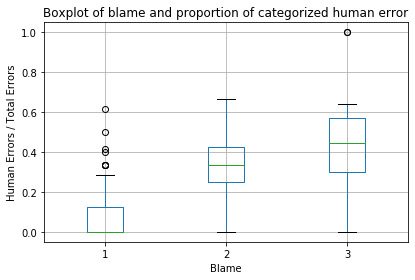

In [60]:
# boxplot of blame vs prop

matad.boxplot(column='Human Error Proportion', by='Blame')
plt.title('Boxplot of blame and proportion of categorized human error')
plt.xlabel('Blame')
plt.ylabel('Human Errors / Total Errors')
plt.tight_layout()
plt.suptitle('')
plt.savefig('error_blame.png')
plt.show()

The median human error proportion increases with blame, which is to be expected if the proportion accurately reflects blame associated with humans for each incident. However, looking at the distributions for each blame level, there are numerous outliers for blame 1 and a right tail, but no significant outliers for blame 2 and blame 3 (the numerical outlier for blame 3 has no significant implication, as it reflects complete human error, which is consistent with a blame level of 3). This could indicate that the dataset overestimates human error in cases of lower blame. To investigate this further, we split the dataset by blame level to conduct logistic regression on each blame distribution.

In [61]:
# log reg for blame 1

# set x to prop and y to blame == 1 (boolean)
X = matad[['Human Error Proportion']]
y_1 = (matad['Blame'] == 1).astype(int)

# split into train and test sets
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(X, y_1, test_size=0.2, random_state=0)

# train logistic regression model on training data
model_1 = LogisticRegression().fit(X_train_1, y_train_1)

# accuracy on test set
model_1.score(X_test_1, y_test_1)

0.6808510638297872

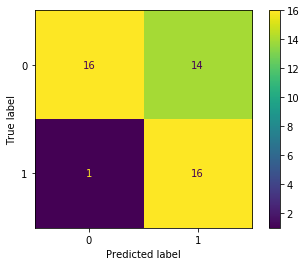

In [62]:
# get predictions for test set
y_pred_1 = model_1.predict(X_test_1)

# confusion matrix for blame 1
ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test_1, y_pred_1), display_labels=sorted(set(y_test_1))).plot()
plt.show()



In [63]:
# log reg for blame 2

y_2 = (matad['Blame'] == 2).astype(int)

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(X, y_2, test_size=0.2, random_state=0)

model_2 = LogisticRegression().fit(X_train_2, y_train_2)

model_2.score(X_test_2, y_test_2)

0.5319148936170213

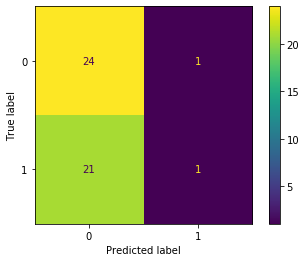

In [64]:
# confusion matrix for blame 2

y_pred_2 = model_2.predict(X_test_2)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test_2, y_pred_2), display_labels=sorted(set(y_test_2))).plot()
plt.show()

In [65]:
# log reg for blame 3

y_3 = (matad['Blame'] == 3).astype(int)

X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(X, y_3, test_size=0.2, random_state=0)

model_3 = LogisticRegression().fit(X_train_3, y_train_3)

model_3.score(X_test_3, y_test_3)

0.8297872340425532

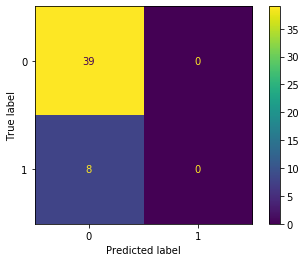

In [66]:
# confusion matrix for blame 3

y_pred_3 = model_3.predict(X_test_3)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test_3, y_pred_3), display_labels=sorted(set(y_test_3))).plot()

plt.show()

In [67]:
# count values per blame level

matad['Blame'].value_counts().rename('Count').reset_index().style.hide_axis=()

The logistic regression model for blame 1 (Figure 3) was by far the most accrate at classifying positive instances. Blame 2 and blame 3 classified all or almost all instances as negative (Figures 4 and 5). Given the distributions of the confusion matricies for the latter two models, we believe that the low accuracy may be caused by the high prevalence of high blame incidents in the dataset, with over half of datapoints labeled as blame 1 (132/231).

In [68]:
# gaussian naive bayes model for all 3 blame levels

y_gnb = matad['Blame']

X_train_gnb, X_test_gnb, y_train_gnb, y_test_gnb = train_test_split(X, y_gnb, test_size=0.2, random_state=0)

# train on training set with equal priors to remove effect of prevalence
model_gnb = GaussianNB(priors=[1/3, 1/3, 1/3]).fit(X_train_gnb, y_train_gnb)

model_gnb.score(X_test_gnb, y_test_gnb)

0.7446808510638298

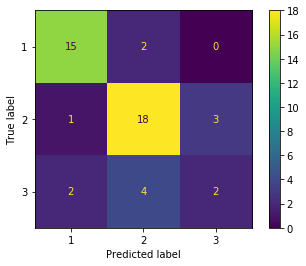

In [69]:
# confusion matrix for gnb

y_pred_gnb = model_gnb.predict(X_test_gnb)
ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test_gnb, y_pred_gnb), display_labels=sorted(set(y_test_gnb))).plot()

Even with a Gaussian Naive Bayes classifier with equal priors, instances of blame 3 are not accurately predicted, with only 2 of 8 incidents correctly categorized as high blame. However, accuracy increased for instances of medium blame, with 18 of 22 instances correctly classified, which is comparable to 15 of 17 for low blame.

In [70]:
#selecting appropriate columns
year_mata = matad[['Year', 'Human Errors', 'Machine Errors', 'Organization Errors']]

#count number of accidents
year_mata['Num Accidents'] = 1

#groupby year
year_mata = year_mata.groupby('Year').sum()

#calculate the proportion of human error
year_mata['Proportion'] = year_mata['Human Errors'] / (year_mata['Human Errors'] + year_mata['Machine Errors'] + year_mata['Organization Errors'])

#filter out years with less than 5 accidents
year_mata_filtered = year_mata[year_mata['Num Accidents'] >= 5].sort_values('Year')

year_mata_filtered

,Human Errors,Machine Errors,Organization Errors,Num Accidents,Proportion
Year,,,,,
1975,11,4,18,6,0.333333
1987,12,13,24,8,0.244898
1988,14,9,24,6,0.297872
1989,7,6,15,6,0.250000
1991,5,7,11,6,0.217391
1992,3,9,14,6,0.115385
1998,14,13,36,10,0.222222
1999,6,7,18,7,0.193548
2001,13,13,30,9,0.232143


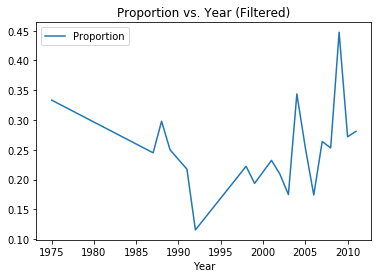

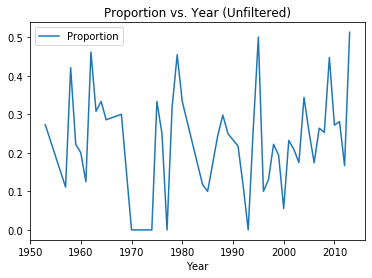

In [71]:
year_mata_filtered.plot(y='Proportion', title='Proportion vs. Year (Filtered)')
year_mata.plot(y='Proportion', title='Proportion vs. Year (Unfiltered)')

In [72]:
np.mean(year_mata['Proportion'])

0.23663277379550376

Observations:

We are filtering out any years that have fewer than 5 accidents since those years likely do not have enough data to extrapolate trends from.

Preliminary analysis doesn't show any particular trends in proportion of categorized errors without further modelling, as can be seen in both the filtered and unfiltered graph.

The mean proportion of human errors in each year varies quite a bit, with a low of around .11 and a high of almost .45.

In [73]:

#only look at these columns
industry_mata = matad[['Industry', 'Human Errors', 'Machine Errors', 'Organization Errors']]

#count num of accidents
industry_mata['Num Accidents'] = 1

#groupby industry
industry_mata = industry_mata.groupby('Industry').sum()

#find the proportion of human error
industry_mata['Proportion'] = industry_mata['Human Errors'] / (industry_mata['Human Errors'] + industry_mata['Machine Errors'] + industry_mata['Organization Errors'])

#ignore all industires that have less than 5 accidents, and organize rows by number of accidents
industry_mata = industry_mata[industry_mata['Num Accidents'] > 5].sort_values('Num Accidents')

industry_mata


,Human Errors,Machine Errors,Organization Errors,Num Accidents,Proportion
Industry,,,,,
Metallurgical Industry,6,9,38,7,0.113208
Gas Processing,4,10,24,9,0.105263
Aviation,65,23,57,13,0.448276
Construction,15,7,46,14,0.220588
Terminals And Distribution,25,23,56,14,0.240385
Nuclear,44,30,92,23,0.265060
Petrochemicals,29,35,65,24,0.224806
Chemicals Factory,52,39,141,29,0.224138
Upstream,66,42,120,36,0.289474


In [74]:
np.sum(industry_mata['Num Accidents'])

206

In [75]:
#calculate average proportion across all industries

np.mean(industry_mata['Proportion'])

0.23661974755714987

We ignored all industries that have less than 5 accidents because we believe there is not enough data to make a reasonable assumption on the consistency of the frequency of human error. All industries that have 10 or more accidents (Refinery, Upstream, Chemicals Factor, Petrochemicals, Nuclear, Terminals and Distribution, Construction and Aviation) except for Aviation have a proportion of human error around 20-30%. Other noticeable industries are that Aviation is around 45% and both Metallurgical Industry and Gas Processing are around 10%.

# Discussion
The low accuracy for high blame incidents, even with equal priors, is possibly due to the very low prevalence of blame 3 in the dataset, which may have led to increased noise and led to difficulty distinguishing high blame incidents. As previously shown in Figure 4, there is also a large overlap in the ranges of blame levels 2 and 3, which could offer another explanation for the low accuracy for high blame incidents. In part, this could be because of MATA-D equally weighting errors, which could lead to similar proportions for blame 2 and 3 incidents despite varying levels of actual human responsibility.

Most of the industries in MATA-D with adequate accidents are ranging around 20-30% for human error, indicating this may be the expected range for major accidents in these industries. We believe the increase in human categorization for error in Aviation is occurring because there is greater responsibility on one human to observe all technology and environmental deviations. The decision-making of a pilot more greatly impacts the consequences of the accident compared to other occupations. Additionally, more blame may be placed on humans in Aviation because there poses a greater danger to the occupants of the plane. We believe less blame is placed on humans for the metallurgical and gas processing industries because it may be harder for people to detect when a mistake has been made or a technological error has occurred. Additionally, there may be a greater gap in knowledge for the people involved in the accident so errors are shifted to being organizational instead of human.